# DM_simulation — the constrained Gadget-4 box, run through notebooks 06 and 07

**Exploratory twin of notebooks
[06](06_velocity_frame_comparison.ipynb) and [07](07_redshift_space_comparison.ipynb),
on a different simulation.** Every stage below is the *same library function* those two
notebooks call — `run_both_frames`, `normalize_comparison`, `make_comparison_figure`,
`build_tracer_spaces`, `run_both_spaces`, `make_redshift_comparison_figure` — with no
estimator forked and no pipeline logic reimplemented here (CLAUDE.md: one library, two thin
consumers). The **only** thing that changes is the loader.

That is possible because both pipelines take `observer` and `n_bar` as explicit arguments at
every stage. The one place either of them reaches for MDPL2 is its loader, so
`dvcorr.pipeline.dm_snapshot` supplies two replacements —
`load_and_carve_particles` and `load_and_carve_particles_buffered` — and everything
downstream is called verbatim. Read that module's docstring first; it is the authority on
what differs and why nothing in `dvcorr.conventions` had to be edited to get here.

## What this simulation is

`data/DM_simulation.hdf5` is a Gadget-4 snapshot at z = 0: 256³ dark-matter particles in a
**300 h⁻¹ Mpc** periodic box, Ωm = 0.308, h = 0.678. Its initial-conditions filename
(`IC_const_gadget4_2mrs_ichain0_L300.0`) identifies it as a **constrained realization built
from 2MRS** — one sample from a reconstruction chain — so unlike MDPL2 it is a mock of *our
actual* local volume rather than a statistically equivalent random box, and the box centre is
intended to be **us**. That provenance is read off a filename, not stated by the file; it is
worth confirming before anything leans on it.

## Three things that are different from 06/07, and change how the plots read

**1 — b = 1.** The tracer field *is* the matter field. There is no halo bias between the
density and the velocity, which is the reason to run this box at all: every MDPL2
measurement in this project is of biased tracers, and this one is not. The dipole measured
here is the matter–velocity dipole, and it is the natural calibration target for
[09](09_galaxy_bias.ipynb).

**2 — the centres are particles, not halos.** A centre drawn from this field is a random
*particle*, so the centre population samples the matter field **by mass**, and its velocity is
its halo's bulk flow **plus its own virial velocity**. The virial part is uncorrelated with
the surrounding large-scale density: it tilts the axis away from the flow (diluting the
dipole) while raising the |v| weight of centres in dense regions. Both act the same way in
every shell, so they rescale the amplitude rather than bend it. Do **not** read a smaller
ζ̂₁ here than in 06 as a statement about the density field.

**3 — the box is 3.3× smaller in each dimension.** `MAX_ANALYSIS_RADIUS` is 150 h⁻¹ Mpc
here, not 500, and the analysis geometry has to fit inside it *twice over* for the
redshift-space half (carve, then buffer). That is what forces the parameters below away from
06/07's defaults — see "Parameters".

## Sign

Unchanged, and still the gate. Both frames are **positive** for coherent infall: mass flows
toward overdensities, so the density excess lies ahead of the flow (velocity frame), and
ζ_ℓ = (−1)^ℓ ξ_Tu,ℓ flips hard rule 2's negative group-centred ξ_Tu,1 into a positive ζ₁
(observer frame). A negative dipole from either frame **on a resolved shell** is an
orientation bug, not a result. The qualifier matters here in a way it did not in 06: the
innermost bin sits below this box's resolution floor, and §B shows a genuine, physical sign
flip in redshift space that is neither.

In [1]:
%matplotlib inline

import numpy as np

from dvcorr.config import PathsConfig, ShellConfig, SPACING_LOG
from dvcorr.estimators.shell_dipole import expected_shell_occupancy
from dvcorr.pipeline.dm_snapshot import (
    read_snapshot_header,
    snapshot_observer,
    snapshot_number_density,
    load_and_carve_particles,
    load_and_carve_particles_buffered,
    DEFAULT_SUBSAMPLE_FACTOR,
)
from dvcorr.pipeline.velocity_centered import draw_candidates_from_arrays, select_shared_centers
from dvcorr.pipeline.velocity_frame_comparison import (
    ComparisonRunConfig,
    run_both_frames,
    normalize_comparison,
    make_comparison_figure,
    make_angle_diagnostic_figure,
)
from dvcorr.pipeline.redshift_space_comparison import (
    RedshiftSpaceRunConfig,
    build_tracer_spaces,
    select_redshift_shared_centers,
    run_both_spaces,
    normalize_redshift_comparison,
    membership_diagnostics,
    make_redshift_comparison_figure,
    make_single_center_figure,
)

paths = PathsConfig()
print("snapshot:", paths.dm_snapshot)

snapshot: /home/ofeke2000/Cross-correlating-Tempel-SDSS-groups-with-Cosmicflows-4-peculiar-velocities/data/DM_simulation.hdf5


## The box, read from its own header

`read_snapshot_header` reads the `Header` and `Parameters` attribute groups and nothing else
— no particle data is touched, so this is instant and can be done before deciding whether the
run's radii even fit. Nothing below is typed in by hand: a hand-copied box size or particle
mass is a silent multiplicative factor on every normalized amplitude, and the file states
both. The loader also **checks the code units** against Gadget's own `Parameters` rather than
assuming them, because a snapshot written in kpc/h would load without error and produce a
plausible-looking curve at the wrong scale.

`snapshot_observer` is this box's counterpart to `conventions.OBSERVER_POSITION` — same
convention (one observer per run, at the box centre), different box. It is passed into the
`observer` argument every downstream stage already has; nothing is redefined locally.

In [2]:
box = read_snapshot_header(paths.dm_snapshot)
observer = snapshot_observer(box)

print(f"box_size                  : {box.box_size:.0f} h^-1 Mpc      (MDPL2: 1000)")
print(f"max_analysis_radius       : {box.max_analysis_radius:.0f} h^-1 Mpc      (MDPL2: 500)")
print(f"observer                  : {observer}   (MDPL2: [500 500 500])")
print(f"n_particles               : {box.n_particles:,}  = {round(box.n_particles ** (1/3)):d}^3")
print(f"particle_mass             : {box.particle_mass:.3e} h^-1 M_sun  (MDPL2: 1.505e+09)")
print(f"mean interparticle spacing: {box.mean_interparticle_spacing:.3f} h^-1 Mpc")
print(f"softening                 : {box.softening:.2f} h^-1 Mpc")
print(f"n_bar (full snapshot)     : {box.number_density:.4f} (h^-1 Mpc)^-3  (MDPL2 full: 0.1274)")
print()
print(f"redshift  : {box.redshift:.3e}   scale factor : {box.scale_factor:.12f}")
print(f"cosmology : Om0 = {box.omega_m}, OmL = {box.omega_lambda}, Ob0 = {box.omega_baryon}, h = {box.hubble_param}")
print(f"            (MDPL2: Om0 = 0.307115, h = 0.6777 -- this is a DIFFERENT cosmology,")
print(f"             which is why dvcorr.config.CosmologyConfig is not used on this path)")
print()
print("initial conditions:")
print(f"  {box.initial_conditions}")
print("  ^ 'IC_const_... 2mrs ...' -- a CONSTRAINED realization from 2MRS, not a random box.")

box_size                  : 300 h^-1 Mpc      (MDPL2: 1000)
max_analysis_radius       : 150 h^-1 Mpc      (MDPL2: 500)
observer                  : [150. 150. 150.]   (MDPL2: [500 500 500])
n_particles               : 16,777,216  = 256^3
particle_mass             : 1.370e+11 h^-1 M_sun  (MDPL2: 1.505e+09)
mean interparticle spacing: 1.172 h^-1 Mpc
softening                 : 0.20 h^-1 Mpc
n_bar (full snapshot)     : 0.6214 (h^-1 Mpc)^-3  (MDPL2 full: 0.1274)

redshift  : 2.220e-16   scale factor : 1.000000000000
cosmology : Om0 = 0.308, OmL = 0.692, Ob0 = 0.0482, h = 0.678
            (MDPL2: Om0 = 0.307115, h = 0.6777 -- this is a DIFFERENT cosmology,
             which is why dvcorr.config.CosmologyConfig is not used on this path)

initial conditions:
  /home/adi/gadget4/examples/2mrs_L300/IC_ichain0/IC_const_gadget4_2mrs_ichain0_L300.0_eps_last_ichain0
  ^ 'IC_const_... 2mrs ...' -- a CONSTRAINED realization from 2MRS, not a random box.


## Parameters

Four deviations from 06/07's defaults, every one of them forced by the box or by the
resolution rather than chosen for taste.

| knob | 06/07 | here | why |
|---|---|---|---|
| `shells.max_radius` | 64 | **40** | The core cut keeps only centres whose outermost shell fits inside the carve, so the usable centre fraction is `((R_sub − r_max) / R_sub)³`. In a box where `R_sub ≤ 150`, `r_max = 64` leaves too little core — and §B needs room for the buffer on top. |
| `sub_volume_radius` | 300 | **130** | Must clear `max_analysis_radius = 150`, and in §B the **buffered** radius `R_sub + v_margin` is the one that has to fit. 130 + 15.5 = 145.5, inside 150 with room. |
| `shells.min_radius` | 1.0 | **2.0** | `box.mean_interparticle_spacing` is 1.17 h⁻¹ Mpc — the scale below which this is not a density field but a list of particles. 06's floor of 1.0 sits *below* it. Not the softening (0.20), which is 6× finer and not the binding constraint. |
| `v_margin_statistic` | `"max"` | **`"percentile"`** | §B only. The fastest particle in the carve moves at ~2900 km/s, so a `"max"` margin is ~29 h⁻¹ Mpc and buffers straight through the box ceiling. See §B. |

`n_candidate_centers` stays at 16000, and the core cut keeps ~33% of them (`(90/130)³`)
against MDPL2's 48% — the geometric price of the small box, and it costs a factor ~1.2 on
every error bar. `subsample_factor` (below) thins the particle field: independent Bernoulli
thinning changes no correlation function, only shot noise, so ζ̂₁ is unchanged in expectation
at 1/N the runtime — and at n̄ ≈ 0.21 the thinned field is still 1.6× denser than MDPL2's
full halo catalog, so the noise it adds was already negligible.

The `[0, min_radius)` bin is kept (`include_zero_bin=True`) so the **unresolved** regime is
shown rather than hidden, exactly as 06 shows its one-halo bins. Read it as a resolution
artifact, not a measurement.

⏱ Expect ~3 minutes for §A and ~2 for §B at these settings, plus ~15 s per load.

In [3]:
# Shared by both halves, so the two are directly comparable to each other.
shells = ShellConfig(
    min_radius=2.0,      # > box.mean_interparticle_spacing = 1.17; see the table above
    max_radius=40.0,
    spacing=SPACING_LOG,
    n_bins=12,
    include_zero_bin=True,
)
SUB_VOLUME_RADIUS = 130.0

cfg = ComparisonRunConfig(sub_volume_radius=SUB_VOLUME_RADIUS, shells=shells)

print(cfg.shells)
print()
print("shell_edges        :", np.round(cfg.shells.shell_edges, 2))
print("sub_volume_radius  :", cfg.sub_volume_radius, "h^-1 Mpc  (ceiling", box.max_analysis_radius, ")")
print("core radius        :", cfg.sub_volume_radius - cfg.shells.max_radius,
      f"h^-1 Mpc -> {100 * ((cfg.sub_volume_radius - cfg.shells.max_radius) / cfg.sub_volume_radius) ** 3:.1f}% of candidates survive the core cut")
print("n_candidate_centers:", cfg.n_candidate_centers)
print("subsample_factor   :", DEFAULT_SUBSAMPLE_FACTOR,
      f"-> n_bar ~ {box.number_density / DEFAULT_SUBSAMPLE_FACTOR:.3f} (h^-1 Mpc)^-3")
print()
print("resolution floor   : first RESOLVED shell edge is",
      f"{cfg.shells.min_radius:.1f} h^-1 Mpc; the [0, {cfg.shells.min_radius:.1f}) bin is below",
      f"the {box.mean_interparticle_spacing:.2f} h^-1 Mpc interparticle spacing and is shown, not trusted.")

ShellConfig(min_radius=2.0, max_radius=40.0, radii_step=10.0, sigma_star=250.0, spacing='log', n_bins=12, include_zero_bin=True)

shell_edges        : [ 0.    2.    2.57  3.3   4.23  5.43  6.97  8.94 11.48 14.74 18.91 24.28
 31.16 40.  ]
sub_volume_radius  : 130.0 h^-1 Mpc  (ceiling 150.0 )
core radius        : 90.0 h^-1 Mpc -> 33.2% of candidates survive the core cut
n_candidate_centers: 16000
subsample_factor   : 3 -> n_bar ~ 0.207 (h^-1 Mpc)^-3

resolution floor   : first RESOLVED shell edge is 2.0 h^-1 Mpc; the [0, 2.0) bin is below the 1.17 h^-1 Mpc interparticle spacing and is shown, not trusted.


# §A — Observer frame vs. velocity frame

The notebook-06 comparison, on this box. Both frames put a velocity object at the centre of
its own shells and expand the surrounding density in multipoles; both take their **axis from
the object's motion** and weight by a **speed**. They differ in one thing only:

$$\hat z^{\,\rm obs}_\alpha = \mathrm{sign}(u_\alpha)\,\hat n_{V,\alpha},\ \ \text{weight } |u_\alpha|
\qquad\text{vs.}\qquad
\hat z^{\,\rm vel}_\alpha = \frac{\mathbf v_\alpha}{|\mathbf v_\alpha|},\ \ \text{weight } |\mathbf v_\alpha|$$

the radial projection versus the full 3-vector. Comparing them measures what is lost by
having a finite-distance observer who can only see radial velocities — and on a **particle**
field that loss is much larger than it was on halos, because a particle's velocity carries a
virial component that is isotropic with respect to the line of sight and therefore mostly
invisible in `u`. The angle diagnostic in §A.6 is where that shows up.

## A.1 — Load and carve

`load_and_carve_particles` replaces `load_and_carve`. Same contract — read a tracer
population, keep what lies within `sub_volume_radius` of the observer, widen to float64 — and
plain Euclidean distance **is** the minimum image inside the carve, because the loader has
already required `sub_volume_radius ≤ box.max_analysis_radius` (`check_run_geometry`). That
check is the piece `conventions.MAX_ANALYSIS_RADIUS` cannot supply here: the estimators test
against MDPL2's 500, which every radius in a 300 h⁻¹ Mpc box passes trivially, so without a
box-specific ceiling this run would have no effective one at all.

In [4]:
carved = load_and_carve_particles(cfg, box, paths.dm_snapshot)

print()
print(f"n_snapshot : {carved.n_snapshot:,}   (the file)")
print(f"n_total    : {carved.n_total:,}   (after the 1-in-{carved.subsample_factor} thinning -- the count n_bar uses)")
print(f"n_carved   : {carved.n_carved:,}   (inside R_sub = {cfg.sub_volume_radius:.0f})")

carved 1954394 of 5592405 particles within sub_volume_radius = 130.0 h^-1 Mpc (34.95%), subsample 1-in-3 of 16777216

n_snapshot : 16,777,216   (the file)
n_total    : 5,592,405   (after the 1-in-3 thinning -- the count n_bar uses)
n_carved   : 1,954,394   (inside R_sub = 130)


## A.2 — Candidate centres, then the SHARED centre set

Two stages, unchanged from 06 except for what is *not* passed.

`draw_candidates_from_arrays` is the definition site of the seeded draw and requires `mvir`
and `is_distinct` arrays. Neither exists for particles: every particle has the same mass, and
"is this a subhalo" is not a property a particle has. They are supplied here only to satisfy
the signature — a uniform mass and an all-True flag — and **nothing downstream reads them**:
`select_shared_centers` takes its mass and distinctness arguments as optional keywords, and
they are left at `None`. The mass-funnel diagnostics (`dvcorr.pipeline.mass_diagnostics`)
must not be pointed at this pipeline; they would return a one-bar histogram.

`select_shared_centers` then applies, **once**, the core cut (`core_margin = r_max`, so a
surviving centre's full shell fits inside the carve) and the `min_center_speed` floor. Both
frames receive the identical arrays, so the only difference between the two measurements is
the axis and the scalar.

In [5]:
# Required by the shared draw's signature; not read by anything on this path.
# See dvcorr.pipeline.dm_snapshot's "Particles are not halos" for why they are
# not real columns.
uniform_mass = np.full(carved.n_carved, box.particle_mass)
all_distinct = np.ones(carved.n_carved, dtype=bool)

candidates = draw_candidates_from_arrays(cfg, carved.pos, carved.vel, uniform_mass, all_distinct)
print("candidate centers:", candidates.s.shape[0])
print()

centers = select_shared_centers(cfg, candidates.s, candidates.v, observer)
print()
print("n_candidates   :", centers.n_candidates)
print("n_core         :", centers.n_core)
print("n_dropped_slow :", centers.n_dropped_slow)
print("n_centers      :", centers.n_centers, " <- used by BOTH frames")

speeds = np.linalg.norm(centers.v_centers, axis=1)
print()
print(f"center speeds  : min={speeds.min():.1f}  median={np.median(speeds):.1f}  max={speeds.max():.1f} km/s")
print("   (a particle's speed, so this includes virial motion -- notably faster than a halo sample)")

candidate centers: 16000

n_candidates = 16000 -> core cut (core_margin = 40.0) -> n_core = 5514 (34.5% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 5514 (0 dropped as too slow)

n_candidates   : 16000
n_core         : 5514
n_dropped_slow : 0
n_centers      : 5514  <- used by BOTH frames

center speeds  : min=13.7  median=466.6  max=2662.6 km/s
   (a particle's speed, so this includes virial motion -- notably faster than a halo sample)


## A.3 — Run both frames, and all four nulls

`run_both_frames` calls the two estimators on the same arrays and builds the velocity frame's
two nulls. Every null in either frame is a **recombination of arrays the estimator already
returned** — nothing re-queries the KDTree — which is what makes 32 independent draws of each
null affordable, and why each null is reported as a mean over those draws with their spread as
its band rather than as one curve.

The velocity frame needs a **random-axis** null rather than a speed shuffle: it is fully
self-aligned (axis and scalar come from the same vector), so permuting `|v_α|` leaves every
centre's axis–density alignment intact and the positive-definite weight keeps the stack at
`N·⟨|v|⟩·⟨A⟩` — no null at all. Randomizing the axis is the guard against that. See notebook
06 for the full argument; none of it changes on this box.

In [6]:
results = run_both_frames(cfg, centers, carved.pos, observer)

obs_result, vel_result = results.obs_result, results.vel_result
print()
print("obs n_centers :", obs_result.n_centers)
print("vel n_centers :", vel_result.n_centers)

# Occupancy is pure geometry and cannot depend on the axis: a strong invariant.
print("per-center occupancy identical across frames:",
      np.array_equal(obs_result.per_center_count, vel_result.per_center_count))


obs n_centers : 5514
vel n_centers : 5514
per-center occupancy identical across frames: True


## A.4 — Normalize

`snapshot_number_density` replaces `box_number_density` — identical arithmetic (count over
box volume), against `box.box_size` instead of the frozen `conventions.BOX_SIZE = 1000`. It
is fed `carved.n_total`, the count of tracers in the **whole box after the thinning**, not
`box.n_particles`: using the full count against a thinned field would inflate n̄ by
`subsample_factor` and suppress every ζ̂₁ by that flat factor, with no change of shape to
reveal it.

Everything after this point — `normalize_comparison` and both figure builders — is called
exactly as notebook 06 calls it.

In [7]:
n_bar = snapshot_number_density(carved.n_total, box)
comparison = normalize_comparison(cfg, results, n_bar)

print(f"n_bar = {n_bar:.5f} particles per (h^-1 Mpc)^3 "
      f"({carved.n_total:,} / {box.box_size:.0f}^3)")
print()
print("r_cen            :", np.round(comparison.shell_centers, 1))
print("zeta_hat   (obs) :", np.round(comparison.obs.zeta_hat, 1))
print("zeta_hat   (vel) :", np.round(comparison.vel.zeta_hat, 1))
print()
print("null rand  (obs) :", np.round(comparison.obs.zeta_hat_shuffle, 1))
print("   +/- spread    :", np.round(comparison.obs.null_spread_shuffle, 1))
print("null rand  (vel) :", np.round(comparison.vel.zeta_hat_shuffle, 1))
print("   +/- spread    :", np.round(comparison.vel.null_spread_shuffle, 1))
print()
print("monopole   (obs) :", np.round(comparison.obs.monopole_norm, 1))
print("monopole   (vel) :", np.round(comparison.vel.monopole_norm, 1))

n_bar = 0.20713 particles per (h^-1 Mpc)^3 (5,592,405 / 300^3)

r_cen            : [ 1.   2.3  2.9  3.8  4.8  6.2  8.  10.2 13.1 16.8 21.6 27.7 35.6]
zeta_hat   (obs) : [301.9 282.5 239.7 184.4 146.7  91.9  59.7  41.6  35.5  26.1  20.3  14.
   9. ]
zeta_hat   (vel) : [922.  662.3 556.8 438.3 353.  235.2 163.5 126.5 101.5  76.6  62.6  44.6
  33.2]

null rand  (obs) : [-9.4  5.2  5.9  3.3 -1.6  1.4 -0.5 -1.1 -0.6  0.3  0.9  0.8  1.5]
   +/- spread    : [64.  25.1 10.7  7.   4.   3.   2.6  1.5  1.2  1.   0.9  0.5  0.3]
null rand  (vel) : [ 6.3  1.8  2.9 -2.2 -1.   0.8  2.8  0.6  0.3 -0.   0.3  0.1  0. ]
   +/- spread    : [153.   52.3  24.2  20.   14.6   8.2   4.6   3.5   1.8   1.9   1.4   1.
   1. ]

monopole   (obs) : [7461.3 2150.1 1354.8  949.8  723.8  553.8  451.2  383.   340.2  309.2
  296.4  281.   278.3]
monopole   (vel) : [14374.6  4035.6  2552.9  1823.8  1416.8  1076.3   888.4   764.4   678.8
   619.5   591.7   561.    555.5]


## A.5 — The comparison figure

**Top:** ζ̂₁ for both frames with their across-**centre** standard-error bands, and each
frame's two nulls with their across-**realization** bands. The two kinds of band mean
different things: the signal's says how noisy this stack is, a null's is the **noise floor**
— a signal point inside its null's band is not a measurement however far from zero it sits.

**Bottom (hard rule 6 — the dipole never travels alone):** both monopoles, on twin y-axes.
Neither sits at zero: both frames weight by a positive-definite speed, which has no near/far
cancellation available to it, so they asymptote to ⟨|u|⟩ and ⟨|v|⟩.

### What to look at first on *this* box

- **The inner bins are enormous and the monopole is huge there.** On the matter field
  1 + ξ_mm(r) reaches ~17 in the innermost bin against ~1.07 in the outermost. That is real
  clustering of the matter field, not a systematic — but the innermost bin is also *below the
  interparticle spacing*, so it is an unresolved bin sitting on top of a genuinely large
  correlation. Both facts point the same way: do not read it.
- **The nulls are flat and small** across every resolved shell. This box's much higher tracer
  density means the inner-shell null blow-up that dominates notebook 06's §6 discussion is far
  weaker here: n̄V_b in the first resolved bin is ~7 expected pairs, not 0.5.
- **The two frames stay a factor 2–4 apart, and the gap widens slowly with r** (≈2.3 at
  r = 2.3 h⁻¹ Mpc, ≈3.7 by r = 36). It is not a constant rescaling, so it is not *only* the
  |u| ≤ |v| projection factor: the shell-average is what §A.7 reports, and §A.6 decomposes
  where it comes from.

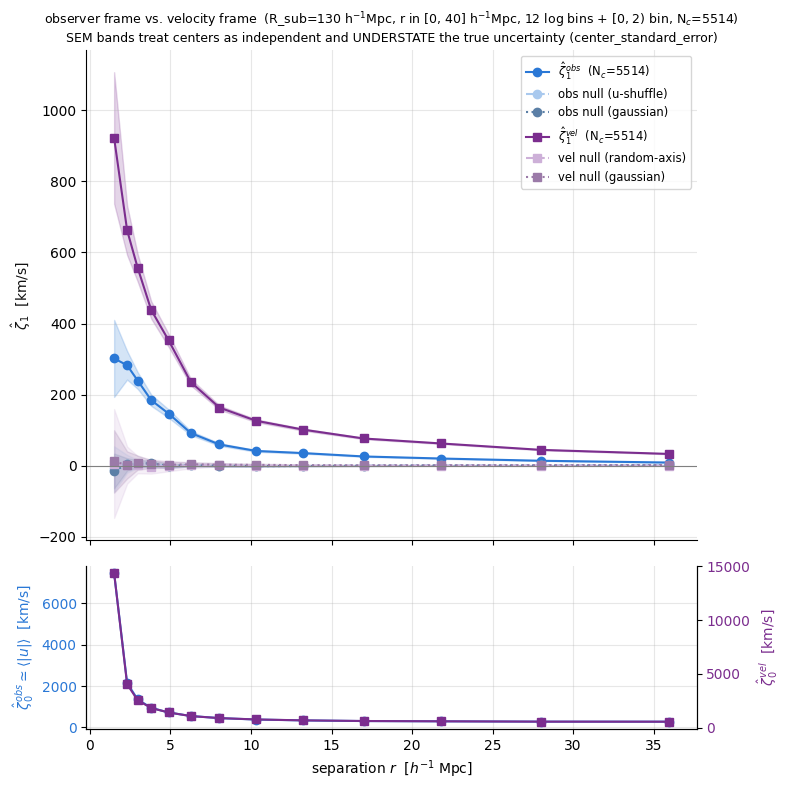

In [8]:
# The figure lives in this notebook's own cell output -- no PNG is written anywhere.
fig = make_comparison_figure(cfg, results, comparison)

## A.6 — Where the gap between the frames comes from

δ_α = arccos(v̂_α · ẑ_α^obs) is the angle between the two frames' axes for each centre. Because
*both* axes follow the motion, cos δ_α = |u_α| / |v_α| ≥ 0 and δ_α is capped at 90°: δ ≈ 0 is
the frame-agreement limit (a purely radial flow, in either direction), δ ≈ 90° is a purely
transverse flow, which the observer frame is blind to entirely.

**This is the diagnostic that most sharply separates a particle field from a halo field.** A
halo's velocity is a coherent bulk flow, so a halo sample sits well below the isotropic
reference. A *particle's* velocity is that bulk flow plus a virial component that has no
preferred orientation with respect to the line of sight — so the δ distribution here should
sit close to the isotropic P(δ) ∝ sin δ curve the bottom panel draws, with only a modest
low-δ excess from the coherent part. The median δ printed in §A.7 is the one-number version.

**Top panel** bins the per-centre dipole difference by δ_α: a few high-δ centres driving the
gap would mean bulk-flow contamination; a smooth spread means genuine projection geometry.

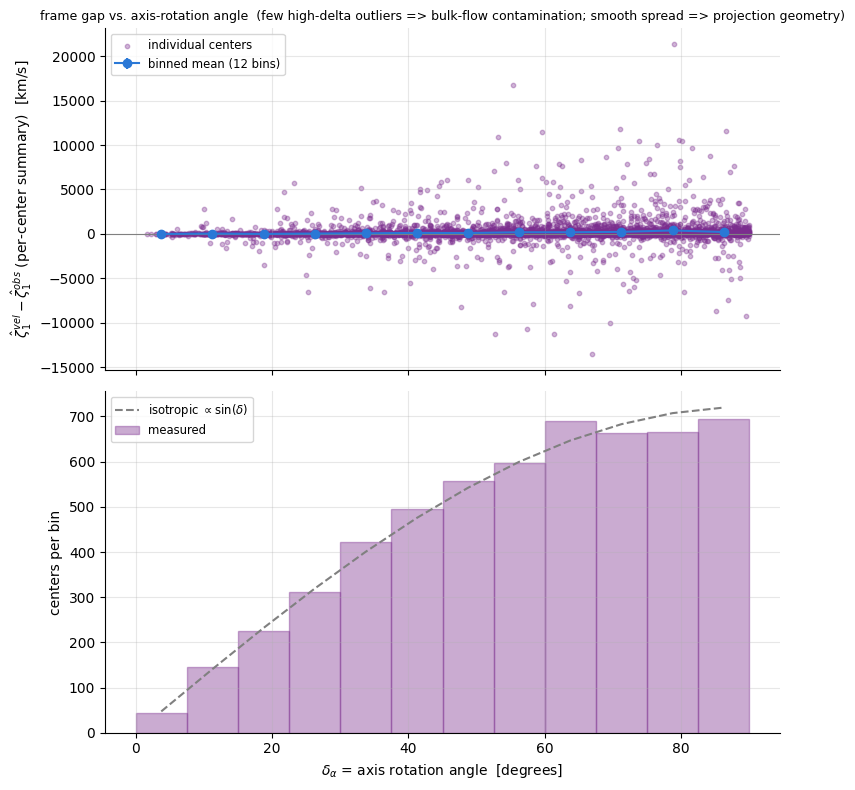

In [9]:
fig_angle = make_angle_diagnostic_figure(cfg, comparison)

## A.7 — Summary numbers

The shell-averaged amplitude of each frame, their ratio, and how far each null sits from zero
**in units of its own across-realization spread** — the right yardstick for a null, since that
spread is exactly how much the curve moves on a change of seed. O(1) means "indistinguishable
from zero", which is what all four should be.

The two mean speeds at the end are worth a second: for a velocity field that is isotropic with
respect to the line of sight, ⟨|u|⟩ / ⟨|v|⟩ = 1/2 exactly (the mean of |cos θ| over a sphere).
Reading close to 0.5 says the centre velocities are close to isotropic about the observer's
lines of sight, which is what a particle field dominated by virial motion should give; a value
meaningfully above 0.5 would mean residual coherent radial flow across the sample.

The resolved-shell mask is applied where it matters: shell-averaging over the unresolved
`[0, min_radius)` bin would let a resolution artifact set the headline number.

In [10]:
delta_deg = np.degrees(comparison.per_center_delta)
resolved = comparison.shell_centers >= cfg.shells.min_radius   # drop the [0, min_radius) bin

print(f"N_c = {centers.n_centers} centers, {resolved.sum()} resolved shells "
      f"({comparison.shell_centers[resolved][0]:.1f} - {comparison.shell_centers[-1]:.1f} h^-1 Mpc)")
print()
mean_obs = np.abs(comparison.obs.zeta_hat[resolved]).mean()
mean_vel = np.abs(comparison.vel.zeta_hat[resolved]).mean()
print(f"shell-averaged |zeta_hat|  obs : {mean_obs:8.2f} km/s")
print(f"shell-averaged |zeta_hat|  vel : {mean_vel:8.2f} km/s")
print(f"                     vel / obs : {mean_vel / mean_obs:8.2f}")
print()
print(f"null / own spread  obs (u-shuffle)   : {np.nanmean(np.abs(comparison.obs.zeta_hat_shuffle) / comparison.obs.null_spread_shuffle):8.2f}")
print(f"null / own spread  obs (gaussian)    : {np.nanmean(np.abs(comparison.obs.zeta_hat_gaussian) / comparison.obs.null_spread_gaussian):8.2f}")
print(f"null / own spread  vel (random-axis) : {np.nanmean(np.abs(comparison.vel.zeta_hat_shuffle) / comparison.vel.null_spread_shuffle):8.2f}")
print(f"null / own spread  vel (gaussian)    : {np.nanmean(np.abs(comparison.vel.zeta_hat_gaussian) / comparison.vel.null_spread_gaussian):8.2f}")
print("   (all four should be O(1) if the nulls are flat)")
print()
print("signal / null spread  obs :", np.round(comparison.obs.zeta_hat / comparison.obs.null_spread_shuffle, 1))
print("signal / null spread  vel :", np.round(comparison.vel.zeta_hat / comparison.vel.null_spread_shuffle, 1))
print()
# The monopole, with matter clustering divided out. Each monopole is (mean SPEED)
# x (occupancy ratio), and that ratio IS 1 + xi_mm(r) -- unbiased here, since the
# tracers ARE the matter. What is left after dividing it out is the genuine
# speed-density correlation, shared by both frames.
occupancy = obs_result.pair_count / (
    obs_result.n_centers * expected_shell_occupancy(n_bar, obs_result.shell_edges)
)
print("occupancy ratio 1+xi_mm(r) :", np.round(occupancy, 3),
      "  <- UNBIASED matter autocorrelation (b = 1)")
print()
obs_resid = comparison.obs.monopole_norm / occupancy
vel_resid = comparison.vel.monopole_norm / occupancy
print("monopole / (1+xi_mm)  obs :", np.round(obs_resid, 1))
print("                      vel :", np.round(vel_resid, 1))
print(f"   residual change over the resolved range   "
      f"obs: {100 * (obs_resid[-1] / obs_resid[resolved][0] - 1):+.1f}%   "
      f"vel: {100 * (vel_resid[-1] / vel_resid[resolved][0] - 1):+.1f}%")
print()
print(f"   <|u|> = {obs_result.per_center_speed.mean():.1f} km/s, "
      f"<|v|> = {vel_result.per_center_speed.mean():.1f} km/s, "
      f"ratio = {obs_result.per_center_speed.mean() / vel_result.per_center_speed.mean():.3f} "
      f"(isotropic expectation: 0.500)")
print()
print(f"delta_alpha : median {np.median(delta_deg):.1f} deg, "
      f"{(delta_deg < 30).sum()} centers below 30 deg, max {delta_deg.max():.1f} deg (ceiling 90)")
print("   (isotropic P(delta) ~ sin(delta) on [0, 90] has median 60.0 deg -- a particle")
print("    field should sit near it; a halo field would sit well below)")

N_c = 5514 centers, 12 resolved shells (2.3 - 35.6 h^-1 Mpc)

shell-averaged |zeta_hat|  obs :    95.96 km/s
shell-averaged |zeta_hat|  vel :   237.85 km/s
                     vel / obs :     2.48

null / own spread  obs (u-shuffle)   :     0.84
null / own spread  obs (gaussian)    :     0.84
null / own spread  vel (random-axis) :     0.14
null / own spread  vel (gaussian)    :     0.79
   (all four should be O(1) if the nulls are flat)

signal / null spread  obs : [ 4.7 11.2 22.4 26.3 36.6 30.8 23.2 28.1 30.6 25.5 21.7 25.6 26.6]
signal / null spread  vel : [ 6.  12.7 23.  21.9 24.2 28.7 35.2 36.3 55.7 41.4 44.8 43.9 34.1]

occupancy ratio 1+xi_mm(r) : [17.689  5.35   3.602  2.717  2.169  1.741  1.495  1.331  1.212  1.143
  1.106  1.075  1.069]   <- UNBIASED matter autocorrelation (b = 1)

monopole / (1+xi_mm)  obs : [421.8 401.9 376.1 349.5 333.8 318.1 301.8 287.8 280.6 270.5 267.9 261.3
 260.5]
                      vel : [812.6 754.4 708.7 671.2 653.3 618.2 594.3 574.3 559.9 541.8

# §B — Real space vs. redshift space

The notebook-07 comparison, on this box. The **same** observer-frame estimator is run twice on
a shared centre set: once on real box positions, once on redshift-space positions — every
particle displaced along its own line of sight by its own radial peculiar velocity
(`dvcorr.redshift_space.to_redshift_space`). The snapshot is at z = 0 exactly, so in comoving
box coordinates that displacement is **exact**, not an approximation, and `v_r / 100` is exact
for any cosmology because H₀ = 100 h km/s/Mpc *is* the definition of h⁻¹ Mpc.

The fact worth carrying into the plots: the displacement is purely radial, so it does not
rotate n̂ — and since u_α = v_α · n̂_V,α depends only on n̂ and v, **u_α is identical between the
two runs**. What changes is *shell composition only*: which tracers land in which radial bin
around a given centre. Never a centre's axis, never its weight.

### Why this box should show a much larger RSD effect than MDPL2 did

The rms radial displacement is σ(v_r) / 100 in h⁻¹ Mpc. On a **particle** field that is the
full one-dimensional velocity dispersion including virial motion — **3.4 h⁻¹ Mpc** for this
centre population, against a fraction of that for a halo catalog whose velocities are bulk
flows. So the fingers-of-God smearing reaches out to separations of order 3–10 h⁻¹ Mpc, which
is a large fraction of the range being measured. Expect the two curves to part company badly at small r
and converge only well beyond that scale. §B.6 puts a number on where.

## B.1 — Buffered load: two carves, one file read

Tracers displace too, so a plain `R_sub` carve leaves the redshift-space tracer field
incomplete at the boundary in *both* directions. The fix is to carve at `R_sub + v_margin`
first, where `v_margin` is derived from the plain carve's own |v_r|.

**`v_margin_statistic = "percentile"`, not the default `"max"`.** This is the one place the
small box genuinely bites. The fastest particle in the carve moves at ~2900 km/s, so a
`"max"` margin is ~29 h⁻¹ Mpc — buffering to 159 h⁻¹ Mpc, past the 150 ceiling, and shrinking
the effective core radius to `130 − (40 + 29) = 61` (an 10% candidate survival). At the 99.9th
percentile the margin is ~15 h⁻¹ Mpc, the buffer lands at ~145 inside the ceiling, and ~19% of
candidates survive.

What that costs is stated rather than hidden: the percentile margin is **not** a true bound on
the displacement, so 0.1% of tracers are still under-buffered and the boundary-flux gap
printed below comes out near 1.5% instead of "well under 1%". The pipeline compensates with a
sign-symmetric, position-independent **global |v_r| cut** on centres — legitimate where a cut
on the displaced position would not be — and prints how many that drops. `check_run_geometry`
re-runs on the buffered radius as soon as it exists, so a margin that would overflow the box
raises rather than silently wrapping.

In [11]:
rcfg = RedshiftSpaceRunConfig(
    sub_volume_radius=SUB_VOLUME_RADIUS,
    shells=shells,
    v_margin_statistic="percentile",   # see the markdown above -- "max" overflows this box
)
print("v_margin_statistic :", rcfg.v_margin_statistic, "at percentile", rcfg.v_margin_percentile)
print()

buffer = load_and_carve_particles_buffered(rcfg, box, paths.dm_snapshot)
print()
print(f"v_margin       = {buffer.v_margin_kms:.1f} km/s = {buffer.v_margin_mpc:.2f} h^-1 Mpc")
print(f"buffered radius = {buffer.buffered_radius:.2f} h^-1 Mpc  (ceiling {box.max_analysis_radius:.0f})")
print(f"effective core  = {rcfg.sub_volume_radius - rcfg.shells.max_radius - buffer.v_margin_mpc:.1f} h^-1 Mpc"
      f" -> {100 * ((rcfg.sub_volume_radius - rcfg.shells.max_radius - buffer.v_margin_mpc) / rcfg.sub_volume_radius) ** 3:.1f}% of candidates")

v_margin_statistic : percentile at percentile 99.9



v_margin (percentile) = 1545.8 km/s = 15.46 h^-1 Mpc; buffered carve: 2680714 particles within 145.46 h^-1 Mpc (ceiling 150), 37.2% more than the plain 130 h^-1 Mpc carve (1954394 particles)

v_margin       = 1545.8 km/s = 15.46 h^-1 Mpc
buffered radius = 145.46 h^-1 Mpc  (ceiling 150)
effective core  = 74.5 h^-1 Mpc -> 18.9% of candidates


## B.2 — Build the tracer fields in both spaces

Displace the **full buffered** tracer field, then restrict back down to `R_sub` — restricting
first would throw away exactly the boundary tracers the buffer exists to keep. The flux check
printed below is this step's trust diagnostic; see B.1 for why it reads ~1.5% here rather than
under 1%, and why that is the percentile margin's known price rather than a misconfiguration.

In [12]:
tracers = build_tracer_spaces(rcfg, buffer, observer)

print()
print(f"real-inside-R_sub = {tracers.n_real_inside:,}, redshift-inside-R_sub = {tracers.n_redshift_inside:,}")

tracer flux check: real-inside-R_sub = 1954394, redshift-inside-R_sub = 1984355 (gap = 1.533%; expected well under 1% -- the buffer captures inflow and outflow both, so a much larger gap means the buffer is misconfigured, not that RSD moved a meaningfully large fraction of the tracer mass); 4 of 2680714 buffered tracers dropped by the through-observer flip guard before the R_sub restriction

real-inside-R_sub = 1,954,394, redshift-inside-R_sub = 1,984,355


## B.3 — Candidates and the shared centre set

Candidates come from the **plain**-radius carve (`buffer.pos_core`), not the buffer: a
candidate centre must itself be a real member of the analysis sub-volume. `mvir_candidates`
and `is_distinct_candidates` are left at `None` — they are optional keywords, and a particle
has neither (§A.2).

Three sequential cuts, all on **real** positions: the core cut at the *widened* margin
`r_max + v_margin`; the global |v_r| cut the percentile statistic requires; and the
through-observer flip guard. Selecting on a *displaced* position would be a real bias, not an
inelegance — it would systematically drop outward-movers near the far boundary while keeping
inward-movers, skewing ⟨u⟩ with position.

In [13]:
uniform_mass_core = np.full(buffer.n_core, box.particle_mass)
all_distinct_core = np.ones(buffer.n_core, dtype=bool)

rs_candidates = draw_candidates_from_arrays(
    rcfg, buffer.pos_core, buffer.vel_core, uniform_mass_core, all_distinct_core
)
print("candidate centers:", rs_candidates.s.shape[0])
print()

rs_centers = select_redshift_shared_centers(
    rcfg, rs_candidates.s, rs_candidates.v, observer, buffer.v_margin_kms, buffer.v_margin_mpc
)
print()
print(f"n_centers = {rs_centers.n_centers} (shared by both spaces)")
print(f"  dropped by the global |v_r| cut : {rs_centers.n_dropped_v_r_percentile}")
print(f"  dropped by the flip guard       : {rs_centers.n_dropped_flip}")

candidate centers: 16000

n_candidates = 16000 -> core cut (core_margin = 55.45800268514934) -> n_core = 3200 (20.0% survive) -> speed floor (min_center_speed = 1.0 km/s) -> n_centers = 3200 (0 dropped as too slow)
redshift-space center selection: base n_centers = 3200 (core_margin = r_max + v_margin = 55.46 h^-1 Mpc) -> global |v_r| <= 1545.8 km/s cut drops 6 -> through-observer guard drops 0 -> n_centers = 3194

n_centers = 3194 (shared by both spaces)
  dropped by the global |v_r| cut : 6
  dropped by the flip guard       : 0


## B.4 — Run both spaces, normalize, plot

`velocity_centered_shell_dipole` is called twice, completely unchanged, with the same
`v_centers`, `shell_edges`, `sub_volume_radius` and `observer`. Both are normalized with the
**same** n̄ — a per-run n̄ would fold the boundary-flux difference into the amplitude ratio,
which is the headline quantity here.

In [14]:
rs_results = run_both_spaces(rcfg, rs_centers, tracers, observer)
print()

rs_n_bar = snapshot_number_density(buffer.n_total, box)
rs_comparison = normalize_redshift_comparison(rcfg, rs_results, rs_n_bar)

print(f"n_bar = {rs_comparison.n_bar:.5f} particles / (h^-1 Mpc)^3")
print()
print("r_cen :", np.round(rs_comparison.shell_centers, 1))
print("real  :", np.round(rs_comparison.real.zeta_hat, 1))
print("rsd   :", np.round(rs_comparison.redshift.zeta_hat, 1))
print("ratio :", np.round(rs_comparison.redshift.zeta_hat / rs_comparison.real.zeta_hat, 2))


n_bar = 0.20713 particles / (h^-1 Mpc)^3

r_cen : [ 1.   2.3  2.9  3.8  4.8  6.2  8.  10.2 13.1 16.8 21.6 27.7 35.6]
real  : [ 80.4 283.  262.3 231.6 166.6  99.8  56.9  44.8  42.5  30.3  22.9  16.6
   9.7]
rsd   : [-185.8 -146.2 -131.2 -105.   -73.9  -43.7  -18.1    0.7   12.9   18.4
   19.2   15.    11.4]
ratio : [-2.31 -0.52 -0.5  -0.45 -0.44 -0.44 -0.32  0.02  0.3   0.61  0.84  0.91
  1.18]


### Reading the figure

**Top:** ζ̂₁ in both spaces with their own SEM bands and their own two nulls (four distinct
random streams). **Bottom:** both monopoles on a *single* shared y-axis — unlike §A.5's twin
axes, these are the same kind of quantity, Σ|u_α| N_α,b, on the **same** u_α values, differing
only through shell occupancy. Any trend difference between the two monopole curves therefore
comes from occupancy alone.

**The redshift-space dipole goes negative at small separations.** That is not an orientation
bug and not a resolution artifact — it is fingers-of-God, and it is the main result of this
half. Around a moving centre, the virial velocities of nearby tracers scatter them along the
line of sight by ~3.4 h⁻¹ Mpc rms, which at small r overwhelms the real infall pattern and
inverts the near/far asymmetry the dipole measures. The monopole panel shows the same event
from the other side: the real-space one-halo pile in the inner bins is smeared *out* in
redshift space, so the redshift-space monopole is **lower** than the real-space one at small r
and higher at intermediate r.

The crossover is the number to take away, and §B.6 prints it: the two curves should agree
again once r is comfortably larger than the rms radial displacement, which is where the
Kaiser (linear, coherent) part of RSD is all that survives.

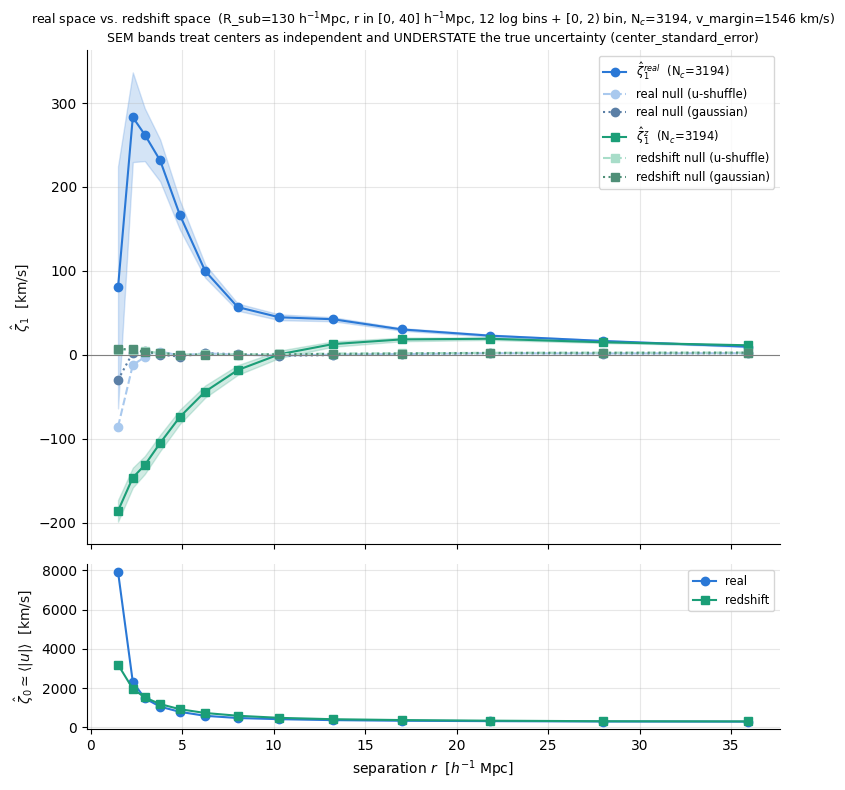

In [15]:
fig_rs = make_redshift_comparison_figure(rcfg, rs_results, rs_comparison)

## B.5 — One centre, and membership churn

The same two-panel layout for a **single** centre (`cfg.example_center_index`), both spaces
overlaid, with no error band — one centre has no across-centre population to form one from.

Then the membership diagnostic: a standalone routine (deliberately *not* part of the
estimator) that re-queries both tracer fields around the shared centres' real positions and
compares shell membership by **stable buffer-row id**, never by array index —
`s_tracers_real` and `s_tracers_redshift` are different subsets of the same buffer, so row *i*
of one and row *i* of the other are, in general, different particles.

`net_change` alone can be near zero while membership churns completely underneath, which is
why the churn columns are reported beside it. On this box the churn should be large at every
radius: a 3.4 h⁻¹ Mpc rms displacement is comparable to or larger than most of the shell widths.

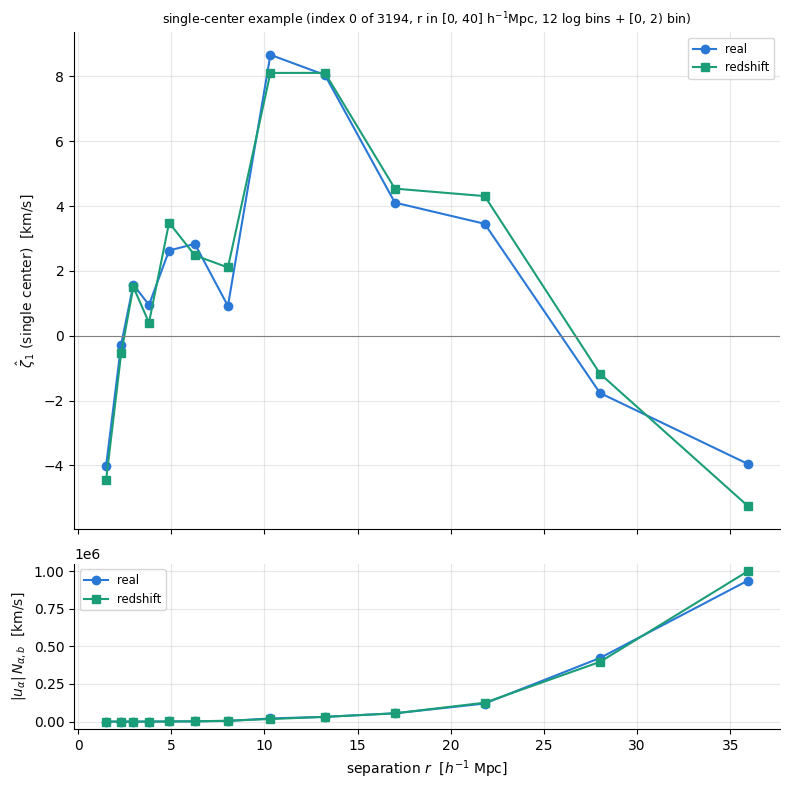

In [16]:
fig_single = make_single_center_figure(rcfg, rs_results, rs_comparison.n_bar)

In [17]:
diagnostics = membership_diagnostics(
    rs_centers.s_centers_real,
    tracers.s_tracers_real, tracers.real_ids,
    tracers.s_tracers_redshift, tracers.redshift_ids,
    rcfg.shells.shell_edges,
)

print(f"{'r':>6}  {'net_change':>12}  {'only_real':>12}  {'only_rsd':>12}  {'both':>12}  {'churn frac':>10}")
for b, r in enumerate(diagnostics.shell_centers):
    only_r = diagnostics.churn_only_real[b]
    only_s = diagnostics.churn_only_redshift[b]
    both = diagnostics.churn_intersection[b]
    frac = (only_r + only_s) / (only_r + only_s + both) if (only_r + only_s + both) else np.nan
    print(f"{r:6.1f}  {diagnostics.net_change[b]:+12.0f}  {only_r:12.0f}  {only_s:12.0f}  {both:12.0f}  {frac:10.3f}")

     r    net_change     only_real      only_rsd          both  churn frac
   1.0       -211478        301419         89941        112569       0.777
   2.3          -848        115299        114451         24122       0.905
   2.9        +27654        154209        181863         45046       0.882
   3.8        +52149        228289        280438         89276       0.851
   4.8        +81335        347849        429184        177482       0.814
   6.2       +136759        521716        658475        354709       0.769
   8.0       +181446        843354       1024800        747847       0.714
  10.2       +215680       1394838       1610518       1641520       0.647
  13.1       +383442       2227428       2610870       3618321       0.572
  16.8       +645945       3579945       4225890       8149254       0.489
  21.6      +1225046       5743446       6968492      18008210       0.414
  27.7      +2173187       9261303      11434490      39226931       0.345
  35.6      +4126394     

## B.6 — Summary numbers

The shell-averaged amplitude in each space, the ratio, and the scale the whole §B story turns
on: the rms radial displacement σ(v_r)/100, in the same h⁻¹ Mpc the shells are binned in. The
crossover radius — where the redshift-space dipole recovers the sign of the real-space one —
is reported against it.

In [18]:
rs_resolved = rs_comparison.shell_centers >= rcfg.shells.min_radius
r_cen = rs_comparison.shell_centers
ratio = rs_comparison.redshift.zeta_hat / rs_comparison.real.zeta_hat

mean_real = np.nanmean(rs_comparison.real.zeta_hat[rs_resolved])
mean_rsd = np.nanmean(rs_comparison.redshift.zeta_hat[rs_resolved])

print(f"N_c = {rs_centers.n_centers} centers (shared), {rs_resolved.sum()} resolved shells")
print(f"v_margin = {rs_centers.v_margin_kms:.1f} km/s = {rs_centers.v_margin_mpc:.2f} h^-1 Mpc")
print()
print(f"shell-averaged zeta_hat_1 : real = {mean_real:.2f} km/s, redshift = {mean_rsd:.2f} km/s, "
      f"ratio = {mean_rsd / mean_real:.3f}")
print()
# The scale the whole section turns on: how far RSD moves a tracer along the line
# of sight. 100 = H0 in km/s per h^-1 Mpc at z = 0 -- definitional, not tunable.
v_r_centers = np.einsum(
    "ij,ij->i",
    rs_centers.v_centers,
    (rs_centers.s_centers_real - observer)
    / np.linalg.norm(rs_centers.s_centers_real - observer, axis=1)[:, None],
)
sigma_v_r = float(np.std(v_r_centers))
print(f"sigma(v_r) over centers      = {sigma_v_r:.1f} km/s")
print(f"  -> rms radial displacement = {sigma_v_r / 100.0:.2f} h^-1 Mpc   <- the fingers-of-God scale")
print()
sign_flip = ratio < 0
if sign_flip[rs_resolved].any():
    last_negative = r_cen[rs_resolved][sign_flip[rs_resolved]].max()
    first_positive = r_cen[rs_resolved][~sign_flip[rs_resolved]].min()
    print(f"redshift-space dipole is NEGATIVE out to r = {last_negative:.1f} h^-1 Mpc, "
          f"positive from r = {first_positive:.1f}")
    print(f"  crossover / rms displacement = {first_positive / (sigma_v_r / 100.0):.1f}")
else:
    print("redshift-space dipole keeps the real-space sign on every resolved shell")
print()
print("ratio by shell :", np.round(ratio, 2))
print(f"tracer flux    : real-inside-R_sub = {tracers.n_real_inside:,}, "
      f"redshift-inside-R_sub = {tracers.n_redshift_inside:,}")

N_c = 3194 centers (shared), 12 resolved shells
v_margin = 1545.8 km/s = 15.46 h^-1 Mpc

shell-averaged zeta_hat_1 : real = 105.59 km/s, redshift = -36.70 km/s, ratio = -0.348

sigma(v_r) over centers      = 336.8 km/s
  -> rms radial displacement = 3.37 h^-1 Mpc   <- the fingers-of-God scale

redshift-space dipole is NEGATIVE out to r = 8.0 h^-1 Mpc, positive from r = 10.2
  crossover / rms displacement = 3.0

ratio by shell : [-2.31 -0.52 -0.5  -0.45 -0.44 -0.44 -0.32  0.02  0.3   0.61  0.84  0.91
  1.18]
tracer flux    : real-inside-R_sub = 1,954,394, redshift-inside-R_sub = 1,984,355


# What this box is for

Three things this run gives that the MDPL2 arm cannot, and one caveat that limits all of them.

**1 — an unbiased calibration point.** The `1 + ξ_mm(r)` occupancy ratio printed in §A.7 is
the *matter* autocorrelation, measured on the same shells and with the same code path as the
halo-biased version notebook 09 works with. That makes it a direct calibration target for
`dvcorr.pipeline.galaxy_bias`: b(r) is the ratio of the two, measured rather than modelled.

**2 — the RSD effect at full strength.** §B's sign flip is the same physics MDPL2 shows
weakly, on a field where the velocity dispersion entering it is the true matter dispersion
rather than a halo catalog's. It is the cleanest available check that the redshift-space
machinery does what it claims.

**3 — a constrained volume.** If the 2MRS provenance is confirmed, this is a mock of the
actual local volume rather than a statistically equivalent one, and its 150 h⁻¹ Mpc reach
brackets CF4's useful depth. That makes it a candidate for a *direct* comparison against the
real measurement later, not only a statistical one. Ask about the rest of the chain: if
`ichain0` is one of several samples, the others are a covariance ensemble — which is exactly
what the empty `mocks/` arm is waiting for.

**The caveat: resolution.** At 1.37e11 h⁻¹ M☉ per particle this box cannot host a halo
catalog comparable to MDPL2's — a 10¹³ h⁻¹ M☉ group is 73 particles, and
`conventions.CONVERGED_PARTICLE_COUNT` = 100 puts the velocity-converged floor at
1.4e13. So this box answers questions about the *matter* field, and MDPL2 answers questions
about *tracers*. Neither substitutes for the other.